# SQL Database Project — Global Semiconductor Supply-Chain Telemetry

**A reproducible, original synthetic-data project using SQLite, Python, SQL, NoSQL and association rules**

**Core deliverables:** a populated SQLite database, a normalized relational schema (with foreign and composite keys), SQL retrieval and integrity tests, data preparation, visual analysis and a document-oriented NoSQL comparison.

> **Academic integrity and provenance:** The Kaggle title provided in the brief is used **only as thematic inspiration**. No Kaggle records, schemas or code are downloaded, imported, copied, modified or used to train the generator. Every observation below is generated from documented probability distributions using a fixed random seed. All companies and facility identifiers are invented. Rerunning this notebook rebuilds its own demonstration tables and outputs.

**Run all cells top to bottom** in Jupyter. The first code cell installs any missing packages. Outputs are saved to the notebook's current working directory; the SQLite file is called `semiconductor_supply_chain.sqlite`.

## 1. Assignment coverage and research context

| Requirement / learning outcome | Where demonstrated |
|---|---|
| SQLite database; at least seven columns and 1,000+ rows | Seven-table database; `telemetry_readings` has 7,200 records and 10 fields |
| Nominal, ordinal, interval and ratio data | Data dictionary below, enforced constraints, validation tests |
| Original randomized data and realistic assumptions | Reproducible generator, weighted scenarios, seasonal variation, noisy sensors |
| Multiple tables, foreign and compound keys | ERD; six cross-table links; `(order_id, line_no)` compound primary key |
| Extract data from SQL | `JOIN`, `GROUP BY`, `CASE`, CTE, parameterized filters and query plan |
| Prepare data for processing | Missing-value checks, cleaning, encoding, derived features |
| Association-rule mining | FP-Growth, support, confidence and lift from shipment event baskets |
| NoSQL understanding and retrieval | TinyDB JSON document store and nested-document queries |
| Justifications, constraints, ethics and privacy | Schema rationale, explicit checks, academic and privacy discussion |

The scenario is a **teaching simulation**, not a claim about actual supplier performance. Semiconductor supply chains involve multiple stages and countries, so the model represents suppliers, fabrication plants (fabs), component categories, orders, shipment movements and environmental telemetry.

In [1]:
# Environment setup. A newly opened Jupyter kernel can execute this cell safely.
# Installation is conditional; installed packages are left unchanged.
import importlib.util
import subprocess
import sys

required = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "mlxtend": "mlxtend", "tinydb": "tinydb",
}
missing = [pip_name for module, pip_name in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already available.")

Installing missing packages: tinydb


In [2]:
from collections import Counter
from datetime import datetime, timedelta
from pathlib import Path
import json
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# All randomness comes from this generator. The same seed produces the same rows.
SEED = 20261105
rng = np.random.default_rng(SEED)
N_ORDERS = 1800
N_CHECKPOINTS = 4
ROOT = Path.cwd()
DB_PATH = ROOT / "semiconductor_supply_chain.sqlite"
NOSQL_PATH = ROOT / "semiconductor_shipments_nosql.json"

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 130)
print("SQLite output:", DB_PATH)

SQLite output: /content/semiconductor_supply_chain.sqlite


## 2. Data types and normalization choices

| Field | Table | Measurement scale | Why it qualifies |
|---|---|---|---|
| `country` | `suppliers` | Nominal | Geographic labels with no natural order |
| `route_mode` | `shipments` | Nominal | Air, Sea, Road are unordered categories |
| `priority` | `purchase_orders` | Ordinal | Routine < Expedited < Critical (order, not equal spacing) |
| `risk_level` | `telemetry_readings` | Ordinal | Low < Moderate < High < Critical |
| `temperature_c` | `telemetry_readings` | Interval | Celsius has an arbitrary zero; 20°C is **not** twice 10°C |
| `humidity_pct` | `telemetry_readings` | Ratio | 0% means no relative humidity; ratios are meaningful on its defined scale |
| `vibration_g` | `telemetry_readings` | Ratio | Zero denotes no measured vibration magnitude |
| `quantity` | `order_lines` | Ratio | Zero items has an absolute meaning (restricted to >0 for orders) |
| `unit_price_usd` | `order_lines` | Ratio | A meaningful zero and additive monetary quantities |

**Why separate tables?** Suppliers and fabs hold stable organization/location attributes, components hold product definitions and standard costs, purchase orders store order headers, order lines represent potentially multiple products per order, shipments track the single simulated dispatch for each order, and telemetry stores four repeated measurements per shipment. Separating these concepts reduces duplicated attributes and prevents update anomalies. For simplicity, each synthetic order is fulfilled by exactly one shipment; partial fulfilment would require a shipment-to-order-line allocation table in a production system.

**Constraint rationale:** PKs ensure entity identity; foreign keys prevent orphaned records; a composite `(order_id, line_no)` key uniquely identifies a line within its order; `UNIQUE` prevents repeated shipment IDs and duplicate checkpoint observations; `NOT NULL`, `CHECK` and indexes protect quality and performance. `PRAGMA foreign_keys=ON` is mandatory per SQLite connection.

## 3. Entity-relationship diagram

The Mermaid source is also provided as a separate `.mmd` file. It is drawn top-to-bottom to remain relatively friendly to portrait A4 layouts; long attribute lists are summarized here, while the SQL below is the full authoritative schema.

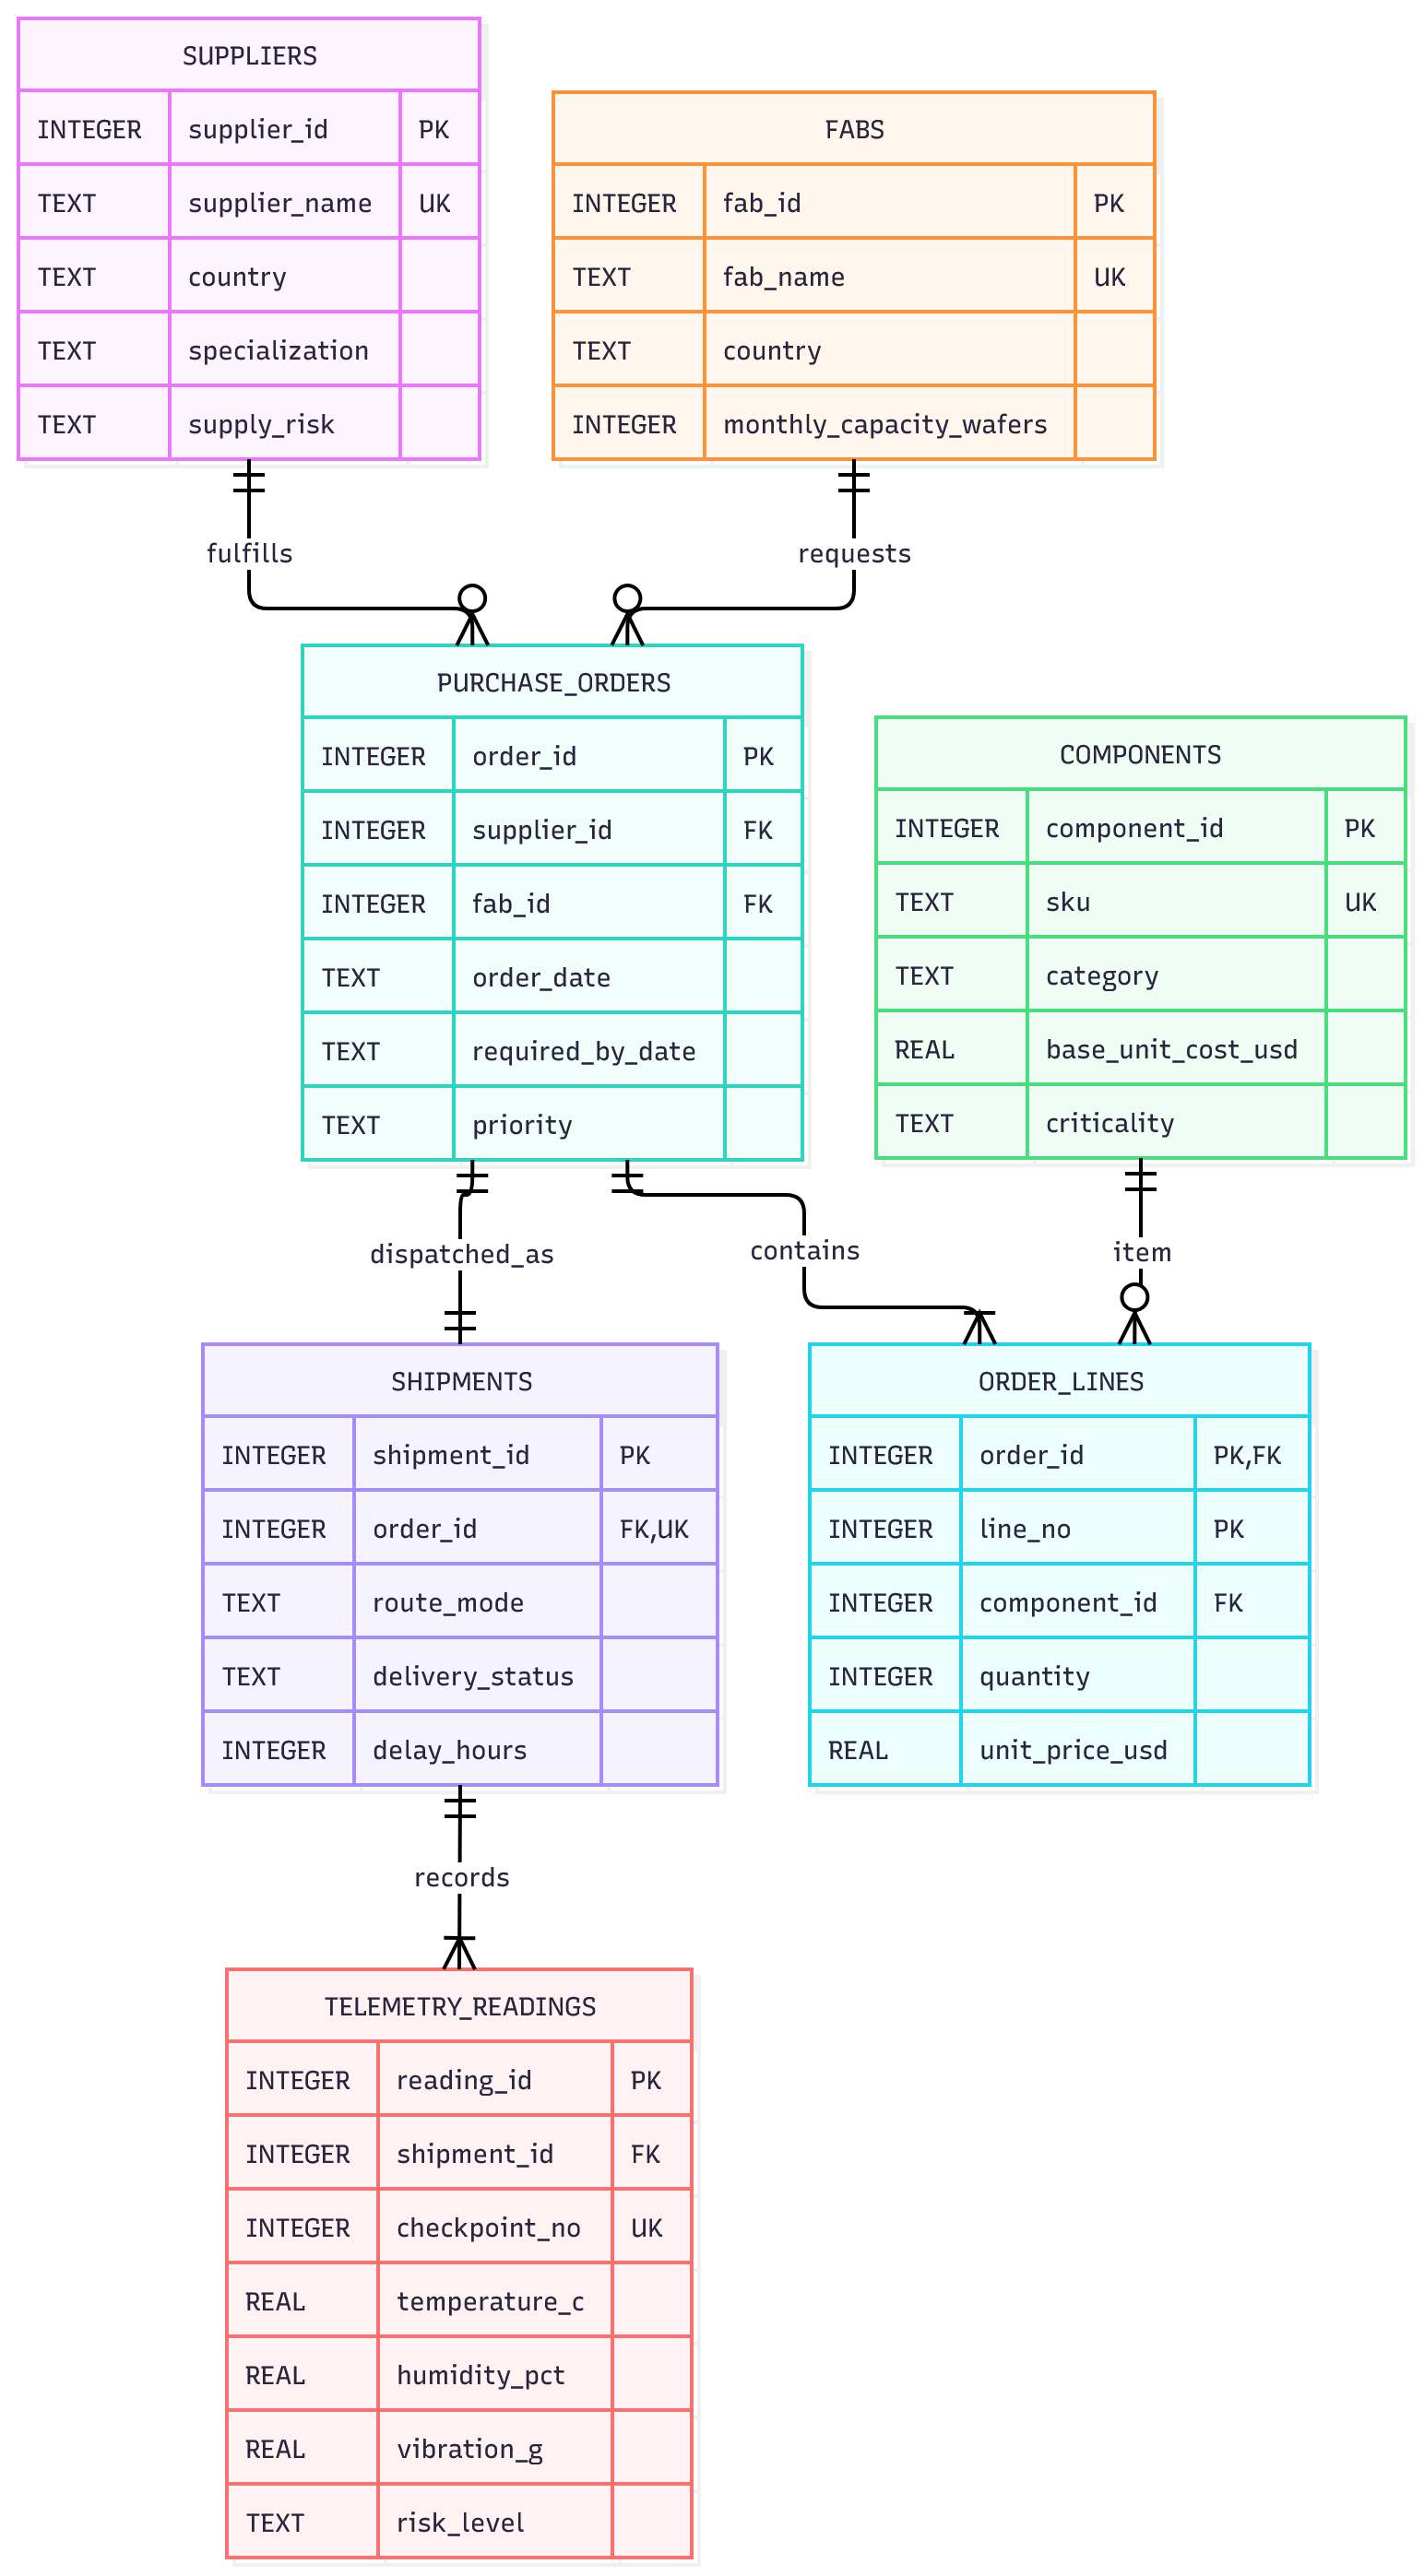

In [3]:
# Each CREATE TABLE is independently documented and uses explicit constraints.
# The DROP order follows children -> parents; it makes reruns deterministic.
SCHEMA_SQL = '''
DROP TABLE IF EXISTS telemetry_readings;
DROP TABLE IF EXISTS shipments;
DROP TABLE IF EXISTS order_lines;
DROP TABLE IF EXISTS purchase_orders;
DROP TABLE IF EXISTS components;
DROP TABLE IF EXISTS fabs;
DROP TABLE IF EXISTS suppliers;

CREATE TABLE suppliers (
    supplier_id INTEGER PRIMARY KEY,
    supplier_name TEXT NOT NULL UNIQUE,
    country TEXT NOT NULL,
    specialization TEXT NOT NULL
        CHECK (specialization IN ('Wafers','Chemicals','Packaging','Equipment')),
    supply_risk TEXT NOT NULL
        CHECK (supply_risk IN ('Low','Moderate','High'))
);

CREATE TABLE fabs (
    fab_id INTEGER PRIMARY KEY,
    fab_name TEXT NOT NULL UNIQUE,
    country TEXT NOT NULL,
    monthly_capacity_wafers INTEGER NOT NULL CHECK (monthly_capacity_wafers > 0)
);

CREATE TABLE components (
    component_id INTEGER PRIMARY KEY,
    sku TEXT NOT NULL UNIQUE,
    component_name TEXT NOT NULL,
    category TEXT NOT NULL
        CHECK (category IN ('Wafers','Chemicals','Packaging','Equipment')),
    base_unit_cost_usd REAL NOT NULL CHECK (base_unit_cost_usd > 0),
    criticality TEXT NOT NULL CHECK (criticality IN ('Low','Medium','High'))
);

CREATE TABLE purchase_orders (
    order_id INTEGER PRIMARY KEY,
    supplier_id INTEGER NOT NULL REFERENCES suppliers(supplier_id),
    fab_id INTEGER NOT NULL REFERENCES fabs(fab_id),
    order_date TEXT NOT NULL,
    required_by_date TEXT NOT NULL,
    priority TEXT NOT NULL CHECK (priority IN ('Routine','Expedited','Critical')),
    CHECK (required_by_date >= order_date)
);

CREATE TABLE order_lines (
    order_id INTEGER NOT NULL REFERENCES purchase_orders(order_id) ON DELETE CASCADE,
    line_no INTEGER NOT NULL CHECK (line_no >= 1),
    component_id INTEGER NOT NULL REFERENCES components(component_id),
    quantity INTEGER NOT NULL CHECK (quantity > 0),
    unit_price_usd REAL NOT NULL CHECK (unit_price_usd > 0),
    PRIMARY KEY (order_id, line_no),
    UNIQUE (order_id, component_id)
) WITHOUT ROWID;

CREATE TABLE shipments (
    shipment_id INTEGER PRIMARY KEY,
    order_id INTEGER NOT NULL UNIQUE
        REFERENCES purchase_orders(order_id) ON DELETE CASCADE,
    route_mode TEXT NOT NULL CHECK (route_mode IN ('Air','Sea','Road')),
    departed_at TEXT NOT NULL,
    arrived_at TEXT NOT NULL,
    planned_transit_hours INTEGER NOT NULL CHECK (planned_transit_hours > 0),
    actual_transit_hours INTEGER NOT NULL CHECK (actual_transit_hours > 0),
    delay_hours INTEGER NOT NULL CHECK (delay_hours >= 0),
    delivery_status TEXT NOT NULL CHECK (delivery_status IN ('On time','Delayed')),
    CHECK (actual_transit_hours = planned_transit_hours + delay_hours),
    CHECK ((delay_hours = 0 AND delivery_status = 'On time') OR
           (delay_hours > 0 AND delivery_status = 'Delayed')),
    CHECK (arrived_at >= departed_at)
);

CREATE TABLE telemetry_readings (
    reading_id INTEGER PRIMARY KEY,
    shipment_id INTEGER NOT NULL REFERENCES shipments(shipment_id) ON DELETE CASCADE,
    checkpoint_no INTEGER NOT NULL CHECK (checkpoint_no BETWEEN 1 AND 4),
    recorded_at TEXT NOT NULL,
    temperature_c REAL CHECK (temperature_c BETWEEN -30 AND 85),
    humidity_pct REAL CHECK (humidity_pct BETWEEN 0 AND 100),
    vibration_g REAL NOT NULL CHECK (vibration_g BETWEEN 0 AND 8),
    shock_event INTEGER NOT NULL CHECK (shock_event IN (0, 1)),
    issue_code TEXT NOT NULL CHECK (issue_code IN
        ('None','Temperature','Humidity','Vibration','Shock')),
    risk_level TEXT NOT NULL CHECK (risk_level IN
        ('Low','Moderate','High','Critical')),
    UNIQUE (shipment_id, checkpoint_no)
);

-- Index foreign keys and common filter columns to support the later queries.
CREATE INDEX idx_orders_supplier_date ON purchase_orders(supplier_id, order_date);
CREATE INDEX idx_orders_fab ON purchase_orders(fab_id);
CREATE INDEX idx_lines_component ON order_lines(component_id);
CREATE INDEX idx_telemetry_shipment ON telemetry_readings(shipment_id);
CREATE INDEX idx_shipments_route_status ON shipments(route_mode, delivery_status);
'''

conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON")
assert conn.execute("PRAGMA foreign_keys").fetchone()[0] == 1
conn.executescript(SCHEMA_SQL)
print("Created seven normalized tables with foreign keys enabled.")

Created seven normalized tables with foreign keys enabled.


## 4. Original data generation — algorithms and assumptions

The synthetic generator below uses `numpy.random.default_rng` with a **fixed seed**. It **does not read any input file**. It builds eight fictional suppliers, six fictional fabs, ten component SKUs, 1,800 purchase orders, 1–3 lines per order, exactly one shipment per order and four telemetry checkpoints per shipment.

The joint distribution is intentionally more realistic than independent uniform random numbers:

1. A supplier can sell only components from its specialization category.
2. Priority and route depend loosely on geography: international critical orders tend to use air transport.
3. Incidents are sampled with route-dependent probabilities. Climate incidents may cause temperature/humidity alerts; handling incidents may cause vibration/shock alerts; border incidents disproportionately cause delay.
4. Sensor readings contain normal noise, occasional missing observations and occasional unusual values. Missing data are allowed only where analytically reasonable.
5. Prices fluctuate around category-specific starting values; positive quantities and transit durations are checked by the database.

Probabilities and values below are **explicit teaching assumptions**, not estimated from real industry operations. The dates cover a synthetic 2025 operating year.

In [4]:
# All suppliers/fabs are fictional names. Countries are broad location labels only.
supplier_rows = [
    (1, 'Aurora Silicon Works', 'Taiwan', 'Wafers', 'Moderate'),
    (2, 'Bluecrest Materials', 'Japan', 'Chemicals', 'Low'),
    (3, 'Orion Packaging Systems', 'Malaysia', 'Packaging', 'Moderate'),
    (4, 'Summit Precision Tools', 'Germany', 'Equipment', 'Low'),
    (5, 'Pacific Substrate Lab', 'South Korea', 'Packaging', 'Moderate'),
    (6, 'Cobalt Process Chemistry', 'Singapore', 'Chemicals', 'Low'),
    (7, 'Northstar Wafer Systems', 'United States', 'Wafers', 'High'),
    (8, 'Helix Equipment Supply', 'Netherlands', 'Equipment', 'Low'),
]
fab_rows = [
    (1, 'Fab Alpha', 'Taiwan', 42000),
    (2, 'Fab Beta', 'South Korea', 36000),
    (3, 'Fab Gamma', 'United States', 30000),
    (4, 'Fab Delta', 'Germany', 28000),
    (5, 'Fab Epsilon', 'Singapore', 25000),
    (6, 'Fab Zeta', 'Malaysia', 22000),
]
component_rows = [
    (1, 'WAF-300', '300 mm silicon wafer', 'Wafers', 125.00, 'High'),
    (2, 'WAF-SOI', 'Silicon-on-insulator wafer', 'Wafers', 275.00, 'High'),
    (3, 'CHM-RES', 'Photoresist batch', 'Chemicals', 60.00, 'High'),
    (4, 'CHM-GAS', 'Process gas cylinder', 'Chemicals', 90.00, 'High'),
    (5, 'CHM-SOL', 'Ultra-pure solvent unit', 'Chemicals', 42.00, 'Medium'),
    (6, 'PKG-SUB', 'Advanced package substrate', 'Packaging', 38.00, 'High'),
    (7, 'PKG-LID', 'Thermal lid assembly', 'Packaging', 22.00, 'Medium'),
    (8, 'PKG-TRAY', 'ESD transport tray', 'Packaging', 8.00, 'Low'),
    (9, 'EQP-PMP', 'Vacuum pump spare', 'Equipment', 1450.00, 'Medium'),
    (10, 'EQP-VLV', 'Precision valve spare', 'Equipment', 740.00, 'Medium'),
]
category_ids = {
    cat: [row[0] for row in component_rows if row[3] == cat]
    for cat in ['Wafers', 'Chemicals', 'Packaging', 'Equipment']
}
component_by_id = {row[0]: row for row in component_rows}
supplier_by_id = {row[0]: row for row in supplier_rows}
fab_by_id = {row[0]: row for row in fab_rows}


def as_timestamp(dt):
    '''Fixed ISO-like format allows lexical time comparisons in SQLite.'''
    return dt.strftime('%Y-%m-%d %H:%M:%S')


order_rows, line_rows, shipment_rows, telemetry_rows = [], [], [], []
start = datetime(2025, 1, 1)
reading_id = 1
incident_counter = Counter()

for order_id in range(1, N_ORDERS + 1):
    supplier_id = int(rng.integers(1, len(supplier_rows) + 1))
    fab_id = int(rng.integers(1, len(fab_rows) + 1))
    supplier = supplier_by_id[supplier_id]
    fab = fab_by_id[fab_id]
    category = supplier[3]
    priority = str(rng.choice(['Routine', 'Expedited', 'Critical'], p=[0.64, 0.25, 0.11]))

    order_dt = start + timedelta(days=int(rng.integers(0, 365)))
    deadline_days = {'Routine': 23, 'Expedited': 12, 'Critical': 7}[priority]
    required_dt = order_dt + timedelta(days=deadline_days)
    order_rows.append((order_id, supplier_id, fab_id, order_dt.date().isoformat(),
                       required_dt.date().isoformat(), priority))

    # Distinct product lines; the supplier's specialization dictates legal SKUs.
    choices = category_ids[category]
    n_lines = int(rng.integers(1, min(3, len(choices)) + 1))
    chosen = rng.choice(choices, size=n_lines, replace=False).tolist()
    for line_no, component_id in enumerate(chosen, 1):
        _, _, _, _, base_cost, _ = component_by_id[int(component_id)]
        if category == 'Equipment':
            quantity = int(rng.integers(1, 21))
        elif category == 'Wafers':
            quantity = int(rng.integers(40, 600))
        else:
            quantity = int(rng.integers(100, 2200))
        unit_price = round(float(base_cost * rng.uniform(0.90, 1.13)), 2)
        line_rows.append((order_id, line_no, int(component_id), quantity, unit_price))

    # Air is more likely for urgent cross-border orders; road for domestic legs.
    same_country = supplier[2] == fab[2]
    if same_country:
        route_mode = str(rng.choice(['Road', 'Air'], p=[0.76, 0.24]))
    elif priority == 'Critical':
        route_mode = str(rng.choice(['Air', 'Sea'], p=[0.88, 0.12]))
    else:
        route_mode = str(rng.choice(['Sea', 'Air'], p=[0.57, 0.43]))

    incident_probs = {
        'Sea': [0.61, 0.13, 0.14, 0.12],
        'Air': [0.75, 0.09, 0.09, 0.07],
        'Road': [0.77, 0.12, 0.08, 0.03],
    }[route_mode]
    incident = str(rng.choice(['None', 'Handling', 'Climate', 'Border'], p=incident_probs))
    incident_counter[incident] += 1

    planned_base = {'Air': 38, 'Sea': 255, 'Road': 29}[route_mode]
    planned_hours = max(8, int(round(planned_base * rng.uniform(0.75, 1.24))))
    probability_delay = {'None': 0.07, 'Handling': 0.55,
                         'Climate': 0.66, 'Border': 0.84}[incident]
    if route_mode == 'Sea':
        probability_delay = min(0.97, probability_delay + 0.08)
    delayed = bool(rng.random() < probability_delay)
    delay_hours = (int(rng.integers(8, 96)) if delayed else 0)
    actual_hours = planned_hours + delay_hours
    departure = order_dt + timedelta(days=int(rng.integers(1, 5)),
                                     hours=int(rng.integers(0, 24)))
    arrival = departure + timedelta(hours=actual_hours)
    delivery_status = 'Delayed' if delayed else 'On time'
    shipment_id = order_id  # one shipment per order in this simplified model
    shipment_rows.append((shipment_id, order_id, route_mode, as_timestamp(departure),
                          as_timestamp(arrival), planned_hours, actual_hours,
                          delay_hours, delivery_status))

    # Each shipment has four distinct measurements, positioned along transit.
    for checkpoint_no in range(1, N_CHECKPOINTS + 1):
        progress = (checkpoint_no - 0.5) / N_CHECKPOINTS
        recorded_at = departure + timedelta(hours=actual_hours * progress)
        season_term = 2.2 * np.sin(2 * np.pi * order_dt.timetuple().tm_yday / 365)
        temp = float(rng.normal(20 + season_term, 3.5))
        humidity = float(rng.normal(43, 7.5))
        vibration = float(max(0, rng.normal(0.23, 0.12)))
        shock = bool(rng.random() < 0.018)

        # Correlated incidents let association mining discover meaningful patterns.
        if incident == 'Climate' and checkpoint_no >= 2:
            temp += float(rng.uniform(9, 17))
            humidity += float(rng.uniform(25, 38))
            # A minority of climate incidents also stress cargo mounting.
            if rng.random() < 0.25:
                vibration += float(rng.uniform(0.8, 1.2))
        if incident == 'Handling' and checkpoint_no >= 2:
            vibration += float(rng.uniform(0.82, 1.65))
            shock = bool(rng.random() < 0.55)
            # Mixed handling/temperature incidents generate some critical flags.
            if rng.random() < 0.24:
                temp += float(rng.uniform(9, 15))

        temp = float(np.clip(temp, -30, 85))
        humidity = float(np.clip(humidity, 0, 100))
        vibration = float(np.clip(vibration, 0, 8))

        # Small missingness simulates device dropout without inventing a value.
        temp_saved = None if rng.random() < 0.018 else round(temp, 2)
        humidity_saved = None if rng.random() < 0.014 else round(humidity, 2)
        shock_event = int(shock)
        alert_temp = temp_saved is not None and temp_saved > 28
        alert_humid = humidity_saved is not None and humidity_saved > 70
        alert_vibration = vibration > 0.85
        alert_count = sum([alert_temp, alert_humid, alert_vibration, bool(shock_event)])
        risk_level = ['Low', 'Moderate', 'High', 'Critical'][min(alert_count, 3)]
        issue_code = ('Shock' if shock_event else 'Vibration' if alert_vibration
                      else 'Temperature' if alert_temp else 'Humidity' if alert_humid
                      else 'None')
        telemetry_rows.append((reading_id, shipment_id, checkpoint_no,
                               as_timestamp(recorded_at), temp_saved, humidity_saved,
                               round(vibration, 3), shock_event, issue_code, risk_level))
        reading_id += 1

print(f"Generated {len(order_rows):,} orders, {len(line_rows):,} order lines, "
      f"{len(shipment_rows):,} shipments, and {len(telemetry_rows):,} telemetry readings.")
print("Synthetic incident counts:", dict(incident_counter))

Generated 1,800 orders, 3,127 order lines, 1,800 shipments, and 7,200 telemetry readings.
Synthetic incident counts: {'None': 1276, 'Climate': 186, 'Handling': 192, 'Border': 146}


In [5]:
# Bulk inserts run inside a transaction. Foreign-key references are valid because
# parent tables are populated before their children.
with conn:
    conn.executemany('INSERT INTO suppliers VALUES (?,?,?,?,?)', supplier_rows)
    conn.executemany('INSERT INTO fabs VALUES (?,?,?,?)', fab_rows)
    conn.executemany('INSERT INTO components VALUES (?,?,?,?,?,?)', component_rows)
    conn.executemany('INSERT INTO purchase_orders VALUES (?,?,?,?,?,?)', order_rows)
    conn.executemany('INSERT INTO order_lines VALUES (?,?,?,?,?)', line_rows)
    conn.executemany('INSERT INTO shipments VALUES (?,?,?,?,?,?,?,?,?)', shipment_rows)
    conn.executemany('INSERT INTO telemetry_readings VALUES (?,?,?,?,?,?,?,?,?,?)', telemetry_rows)

TABLES = ['suppliers', 'fabs', 'components', 'purchase_orders',
          'order_lines', 'shipments', 'telemetry_readings']
table_sizes = pd.DataFrame(
    [(t, conn.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0]) for t in TABLES],
    columns=['table_name', 'row_count']
)
display(table_sizes)

,table_name,row_count
0,suppliers,8
1,fabs,6
2,components,10
3,purchase_orders,1800
4,order_lines,3127
5,shipments,1800
6,telemetry_readings,7200


## 5. Database integrity, completeness and constraint tests

The database should fail quickly if bad records appear. We test SQLite's `integrity_check` and `foreign_key_check`, ensure the required minimum row count, verify the four checkpoint observations per shipment and demonstrate rejection of a duplicate compound-key row. The negative test uses a savepoint to leave the finished database unchanged.

In [6]:
assert conn.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'
assert conn.execute('PRAGMA foreign_key_check').fetchall() == []
assert conn.execute('SELECT COUNT(*) FROM telemetry_readings').fetchone()[0] >= 1000
assert conn.execute('SELECT COUNT(*) FROM telemetry_readings').fetchone()[0] == N_ORDERS * N_CHECKPOINTS
assert conn.execute('SELECT COUNT(DISTINCT shipment_id) FROM telemetry_readings').fetchone()[0] == N_ORDERS
assert conn.execute('SELECT MIN(c) FROM (SELECT COUNT(*) c FROM telemetry_readings GROUP BY shipment_id)').fetchone()[0] == 4

# Verify all four explicitly ordered risk levels are represented in generated records.
risk_counts = pd.read_sql_query('''
    SELECT risk_level, COUNT(*) AS n
    FROM telemetry_readings GROUP BY risk_level
    ORDER BY CASE risk_level WHEN 'Low' THEN 1 WHEN 'Moderate' THEN 2
                             WHEN 'High' THEN 3 ELSE 4 END
''', conn)
assert set(risk_counts['risk_level']) == {'Low', 'Moderate', 'High', 'Critical'}
display(risk_counts)

# A failed INSERT is an expected result, not a notebook failure.
conn.execute('SAVEPOINT constraint_demo')
try:
    try:
        # Component 10 is not present in the first wafer-specialist order.
        # The repeated (order_id, line_no) alone triggers its composite PK.
        conn.execute('INSERT INTO order_lines VALUES (1,1,10,1,1.0)')
        raise AssertionError('Composite PK unexpectedly accepted a duplicate')
    except sqlite3.IntegrityError as exc:
        print('Composite primary key correctly rejected duplicate:', exc)
finally:
    conn.execute('ROLLBACK TO SAVEPOINT constraint_demo')
    conn.execute('RELEASE SAVEPOINT constraint_demo')

print('PASS: primary keys, foreign keys, CHECK constraints, counts and integrity tests.')

,risk_level,n
0,Low,5868
1,Moderate,592
2,High,609
3,Critical,131


Composite primary key correctly rejected duplicate: UNIQUE constraint failed: order_lines.order_id, order_lines.line_no
PASS: primary keys, foreign keys, CHECK constraints, counts and integrity tests.


## 6. SQL extraction — joins, aggregation, subqueries and parameters

Each query answers a practical business question. Queries use SQL rather than computing everything in Python, making the extraction method transparent.

In [7]:
# Query A: Which suppliers have the highest simulated delivery-delay rate?
# GROUP BY aggregates 1,800 shipments through their foreign-key relationships.
supplier_performance = pd.read_sql_query('''
SELECT su.supplier_name, su.country,
       COUNT(*) AS shipment_count,
       ROUND(100.0 * AVG(CASE WHEN sh.delivery_status = 'Delayed'
                             THEN 1 ELSE 0 END), 1) AS delayed_pct,
       ROUND(AVG(sh.delay_hours), 1) AS avg_delay_hours
FROM shipments sh
JOIN purchase_orders po ON po.order_id = sh.order_id
JOIN suppliers su ON su.supplier_id = po.supplier_id
GROUP BY su.supplier_id, su.supplier_name, su.country
ORDER BY delayed_pct DESC, shipment_count DESC
''', conn)
display(supplier_performance)

,supplier_name,country,shipment_count,delayed_pct,avg_delay_hours
0,Pacific Substrate Lab,South Korea,223,31.8,15.5
1,Helix Equipment Supply,Netherlands,227,31.3,14.2
2,Bluecrest Materials,Japan,226,31.0,15.7
3,Summit Precision Tools,Germany,218,28.0,15.6
4,Orion Packaging Systems,Malaysia,226,26.5,12.2
5,Cobalt Process Chemistry,Singapore,236,26.3,14.7
6,Aurora Silicon Works,Taiwan,221,25.8,14.8
7,Northstar Wafer Systems,United States,223,24.2,13.3


In [8]:
# Query B: Where is order-line spending concentrated?
# The composite-key line table is joined to a component dimension.
category_spend = pd.read_sql_query('''
SELECT c.category,
       COUNT(*) AS order_lines,
       SUM(ol.quantity) AS units_ordered,
       ROUND(SUM(ol.quantity * ol.unit_price_usd), 2) AS spend_usd
FROM order_lines ol
JOIN components c ON c.component_id = ol.component_id
GROUP BY c.category
ORDER BY spend_usd DESC
''', conn)
display(category_spend)

,category,order_lines,units_ordered,spend_usd
0,Chemicals,942,1057842,67565392.47
1,Wafers,652,209493,42392030.07
2,Packaging,873,993733,23409666.55
3,Equipment,660,6864,7634363.00


In [9]:
# Query C: Parameterized filtering prevents values from being concatenated into SQL.
route_filter = 'Sea'
start_date = '2025-01-01'
route_sample = pd.read_sql_query('''
SELECT sh.shipment_id, f.fab_name, po.priority, sh.route_mode,
       sh.delivery_status, sh.delay_hours
FROM shipments sh
JOIN purchase_orders po ON po.order_id = sh.order_id
JOIN fabs f ON f.fab_id = po.fab_id
WHERE sh.route_mode = ? AND po.order_date >= ?
ORDER BY sh.delay_hours DESC, sh.shipment_id
LIMIT 12
''', conn, params=(route_filter, start_date))
display(route_sample)

,shipment_id,fab_name,priority,route_mode,delivery_status,delay_hours
0,694,Fab Epsilon,Routine,Sea,Delayed,95
1,1381,Fab Gamma,Expedited,Sea,Delayed,95
2,1403,Fab Alpha,Routine,Sea,Delayed,95
3,1554,Fab Alpha,Routine,Sea,Delayed,95
4,349,Fab Zeta,Routine,Sea,Delayed,94
5,611,Fab Delta,Expedited,Sea,Delayed,94
6,1272,Fab Zeta,Routine,Sea,Delayed,94
7,52,Fab Epsilon,Routine,Sea,Delayed,93
8,877,Fab Alpha,Routine,Sea,Delayed,93
9,970,Fab Gamma,Routine,Sea,Delayed,93


In [10]:
# Query D: Multi-stage analysis with a CTE: sensor alert counts by route.
route_alerts = pd.read_sql_query('''
WITH shipment_alerts AS (
    SELECT shipment_id,
           MAX(CASE WHEN temperature_c > 28 THEN 1 ELSE 0 END) AS temp_alert,
           MAX(CASE WHEN humidity_pct > 70 THEN 1 ELSE 0 END) AS humidity_alert,
           MAX(CASE WHEN vibration_g > 0.85 THEN 1 ELSE 0 END) AS vibration_alert,
           MAX(shock_event) AS shock_alert
    FROM telemetry_readings
    GROUP BY shipment_id
)
SELECT sh.route_mode, COUNT(*) AS shipments,
       SUM(sa.temp_alert) AS temp_alert_shipments,
       SUM(sa.humidity_alert) AS humidity_alert_shipments,
       SUM(sa.vibration_alert) AS vibration_alert_shipments,
       SUM(sa.shock_alert) AS shock_alert_shipments
FROM shipments sh JOIN shipment_alerts sa ON sa.shipment_id = sh.shipment_id
GROUP BY sh.route_mode ORDER BY shipments DESC
''', conn)
display(route_alerts)

# EXPLAIN QUERY PLAN gives evidence of query-execution strategy.
display(pd.read_sql_query('''
EXPLAIN QUERY PLAN
SELECT * FROM shipments WHERE route_mode = 'Air' AND delivery_status = 'Delayed'
''', conn))

,route_mode,shipments,temp_alert_shipments,humidity_alert_shipments,vibration_alert_shipments,shock_alert_shipments
0,Sea,824,214,112,172,144
1,Air,800,143,63,101,117
2,Road,176,21,8,22,21


,id,parent,notused,detail
0,3,0,0,SEARCH shipments USING INDEX idx_shipments_rou...


## 7. Prepare extracted data for onward processing

First retrieve a flat analytical table, with one row per shipment. SQL CTEs pre-aggregate the one-to-many order-line and telemetry tables so joining them does **not** accidentally multiply the number of observations. Then inspect missing values, explicitly encode ordered priorities, and fill sensor missingness for algorithms that cannot handle `NULL` values. We retain raw missingness indicators so imputations are not mistaken for observed data. Averages of four checkpoints can be complete even if some **individual readings** are missing, so we separately inspect those raw observations.

In [11]:
analysis_df = pd.read_sql_query('''
WITH spend AS (
  SELECT order_id, COUNT(*) AS line_count,
         SUM(quantity * unit_price_usd) AS order_value_usd
  FROM order_lines GROUP BY order_id
), sensors AS (
  SELECT shipment_id, AVG(temperature_c) AS mean_temp_c,
         AVG(humidity_pct) AS mean_humidity_pct,
         MAX(vibration_g) AS peak_vibration_g,
         MAX(shock_event) AS any_shock,
         SUM(CASE WHEN temperature_c IS NULL THEN 1 ELSE 0 END) AS missing_temp_n,
         SUM(CASE WHEN humidity_pct IS NULL THEN 1 ELSE 0 END) AS missing_humidity_n,
         MAX(CASE risk_level WHEN 'Low' THEN 1 WHEN 'Moderate' THEN 2
                             WHEN 'High' THEN 3 ELSE 4 END) AS max_risk_score
  FROM telemetry_readings GROUP BY shipment_id
)
SELECT sh.shipment_id, po.order_date, po.priority,
       su.country AS supplier_country, f.country AS fab_country,
       sh.route_mode, sh.delivery_status, sh.delay_hours,
       s.line_count, s.order_value_usd, sen.*
FROM shipments sh
JOIN purchase_orders po ON po.order_id = sh.order_id
JOIN suppliers su ON su.supplier_id = po.supplier_id
JOIN fabs f ON f.fab_id = po.fab_id
JOIN spend s ON s.order_id = po.order_id
JOIN sensors sen ON sen.shipment_id = sh.shipment_id
ORDER BY sh.shipment_id
''', conn, parse_dates=['order_date'])

# Remove repeated shipment_id from the SELECT's 'sen.*' projection (if any).
analysis_df = analysis_df.loc[:, ~analysis_df.columns.duplicated()].copy()
assert len(analysis_df) == N_ORDERS, 'Join multiplicity error: expected one row per shipment'

print('Shape:', analysis_df.shape)
print('Missing values by column:')
display(analysis_df.isna().sum().to_frame('n_missing').query('n_missing > 0'))
display(analysis_df.head())

Shape: (1800, 17)
Missing values by column:


,n_missing


,shipment_id,order_date,priority,supplier_country,fab_country,route_mode,delivery_status,delay_hours,line_count,order_value_usd,mean_temp_c,mean_humidity_pct,peak_vibration_g,any_shock,missing_temp_n,missing_humidity_n,max_risk_score
0,1,2025-12-05,Critical,United States,Singapore,Air,On time,0,2,111965.23,18.2400,45.5625,0.437,0,0,0,1
1,2,2025-05-31,Routine,South Korea,United States,Sea,Delayed,79,2,16634.46,29.9050,69.6275,1.457,0,0,0,4
2,3,2025-04-30,Routine,Malaysia,Malaysia,Road,On time,0,2,45060.14,24.5325,43.5525,0.451,0,0,0,2
3,4,2025-09-13,Expedited,United States,Malaysia,Air,On time,0,1,44176.88,16.8775,35.1650,0.416,0,0,0,1
4,5,2025-07-13,Routine,Japan,United States,Air,On time,0,3,83222.45,21.0875,36.3875,0.415,0,0,0,1


In [12]:
# Missingness is visible at the individual-reading level (before aggregation).
# Keep observed values unchanged; create separate imputed feature columns.
raw_sensors = pd.read_sql_query('''
    SELECT reading_id, shipment_id, temperature_c, humidity_pct, vibration_g
    FROM telemetry_readings ORDER BY reading_id
''', conn)
print('Missing raw telemetry values:')
display(raw_sensors[['temperature_c','humidity_pct']].isna().sum().to_frame('missing_rows'))
for variable in ['temperature_c', 'humidity_pct']:
    raw_sensors[variable + '_missing'] = raw_sensors[variable].isna().astype(int)
    raw_sensors[variable + '_filled'] = raw_sensors[variable].fillna(
        raw_sensors[variable].median()
    )
assert raw_sensors[['temperature_c_filled','humidity_pct_filled']].notna().all().all()
display(raw_sensors[raw_sensors['temperature_c_missing'].eq(1)].head(4))

Missing raw telemetry values:


,missing_rows
temperature_c,144
humidity_pct,108


,reading_id,shipment_id,temperature_c,humidity_pct,vibration_g,temperature_c_missing,temperature_c_filled,humidity_pct_missing,humidity_pct_filled
32,33,9,NaN,47.08,0.335,1,20.54,0,47.08
110,111,28,NaN,18.01,0.103,1,20.54,0,18.01
267,268,67,NaN,44.36,0.000,1,20.54,0,44.36
312,313,79,NaN,48.54,0.275,1,20.54,0,48.54


In [13]:
# Explicitly map ordinal labels; normal one-hot coding avoids inventing an
# order for nominal route categories.
priority_order = {'Routine': 1, 'Expedited': 2, 'Critical': 3}
prepared_df = analysis_df.copy()
prepared_df['priority_score'] = prepared_df['priority'].map(priority_order)
prepared_df['is_delayed'] = (prepared_df['delivery_status'] == 'Delayed').astype(int)
prepared_df['cross_border'] = (prepared_df['supplier_country'] != prepared_df['fab_country']).astype(int)

for col in ['mean_temp_c', 'mean_humidity_pct']:
    prepared_df[col + '_imputed'] = prepared_df[col].isna().astype(int)
    prepared_df[col] = prepared_df[col].fillna(prepared_df[col].median())

prepared_df = pd.get_dummies(prepared_df, columns=['route_mode'], dtype=int)
assert prepared_df['priority_score'].notna().all()
assert prepared_df[['mean_temp_c', 'mean_humidity_pct']].notna().all().all()

EXPORT_DIR = ROOT / 'semiconductor_exports'
EXPORT_DIR.mkdir(exist_ok=True)
prepared_df.to_csv(EXPORT_DIR / 'analysis_ready.csv', index=False)
print('Prepared:', prepared_df.shape, '; exported analysis_ready.csv')
display(prepared_df.head(4))

Prepared: (1800, 24) ; exported analysis_ready.csv


,shipment_id,order_date,priority,supplier_country,fab_country,delivery_status,delay_hours,line_count,order_value_usd,mean_temp_c,mean_humidity_pct,peak_vibration_g,any_shock,missing_temp_n,missing_humidity_n,max_risk_score,priority_score,is_delayed,cross_border,mean_temp_c_imputed,mean_humidity_pct_imputed,route_mode_Air,route_mode_Road,route_mode_Sea
0,1,2025-12-05,Critical,United States,Singapore,On time,0,2,111965.23,18.2400,45.5625,0.437,0,0,0,1,3,0,1,0,0,1,0,0
1,2,2025-05-31,Routine,South Korea,United States,Delayed,79,2,16634.46,29.9050,69.6275,1.457,0,0,0,4,1,1,1,0,0,0,0,1
2,3,2025-04-30,Routine,Malaysia,Malaysia,On time,0,2,45060.14,24.5325,43.5525,0.451,0,0,0,2,1,0,0,0,0,0,1,0
3,4,2025-09-13,Expedited,United States,Malaysia,On time,0,1,44176.88,16.8775,35.1650,0.416,0,0,0,1,2,0,1,0,0,1,0,0


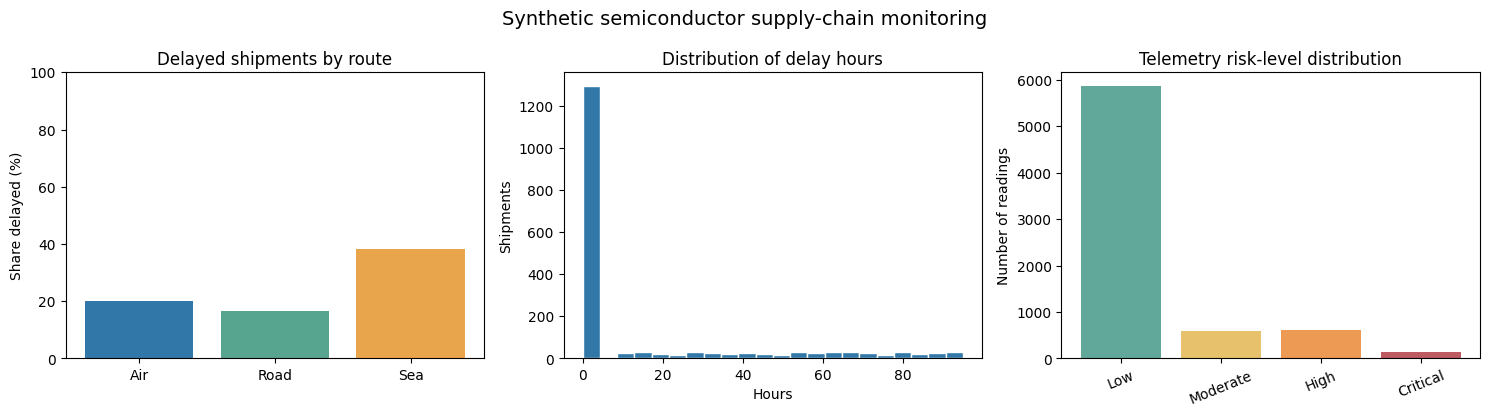

In [14]:
# Exploratory figures are descriptive of synthetic data only.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
display_order = ['Air', 'Road', 'Sea']
rate = analysis_df.groupby('route_mode')['delivery_status'].apply(
    lambda x: 100 * x.eq('Delayed').mean()).reindex(display_order)
axes[0].bar(rate.index, rate.values, color=['#3178a8', '#58a58f', '#e9a54b'])
axes[0].set(title='Delayed shipments by route', ylabel='Share delayed (%)', ylim=(0, 100))

axes[1].hist(analysis_df['delay_hours'], bins=22, color='#3178a8', edgecolor='white')
axes[1].set(title='Distribution of delay hours', xlabel='Hours', ylabel='Shipments')

risk_sizes = risk_counts.set_index('risk_level').reindex(['Low','Moderate','High','Critical'])['n']
axes[2].bar(risk_sizes.index, risk_sizes.values,
            color=['#61a89b', '#e7c16b', '#ed9a55', '#bd5a62'])
axes[2].tick_params(axis='x', rotation=22)
axes[2].set(title='Telemetry risk-level distribution', ylabel='Number of readings')

fig.suptitle('Synthetic semiconductor supply-chain monitoring', fontsize=14)
fig.tight_layout()
fig.savefig(EXPORT_DIR / 'sql_project_summary.png', dpi=170, bbox_inches='tight')
plt.show()

## 8. NoSQL contrast — nested JSON documents with TinyDB

SQLite is relational and enforces cross-table foreign keys; **TinyDB** is a lightweight document-oriented NoSQL database that stores JSON documents and retrieves them through document queries. We deliberately **derive** its records from our own SQL-generated data, avoiding an external dataset. Each shipment document embeds a small sensor summary instead of requiring a SQL join. This is useful for flexible telemetry payloads, but provides weaker cross-document referential integrity, so the relational database remains our authoritative source.

This is a genuine local document store, not a claim that SQLite's JSON columns turn SQLite itself into a NoSQL database. TinyDB demonstrates the NoSQL model without requiring a separately configured MongoDB server.

In [15]:
from tinydb import TinyDB, Query

documents = []
for row in analysis_df.to_dict(orient='records'):
    documents.append({
        'shipment_id': int(row['shipment_id']),
        'route_mode': row['route_mode'],
        'delivery_status': row['delivery_status'],
        'priority': row['priority'],
        'sensor_summary': {
            'mean_temperature_c': (None if pd.isna(row['mean_temp_c'])
                                   else round(float(row['mean_temp_c']), 2)),
            'mean_humidity_pct': (None if pd.isna(row['mean_humidity_pct'])
                                  else round(float(row['mean_humidity_pct']), 2)),
            'peak_vibration_g': round(float(row['peak_vibration_g']), 3),
            'any_shock': bool(row['any_shock']),
            'max_risk_score': int(row['max_risk_score']),
        },
    })

with TinyDB(NOSQL_PATH) as document_db:
    shipment_collection = document_db.table('shipments')
    shipment_collection.truncate()  # replace only this notebook's derived documents on rerun
    shipment_collection.insert_multiple(documents)

    Sh = Query()
    # Nested JSON-like fields can be queried without performing a SQL JOIN.
    critical_documents = shipment_collection.search(
        (Sh.route_mode == 'Sea') & (Sh.sensor_summary.max_risk_score >= 3)
    )
    print('NoSQL document count:', len(shipment_collection))
    print('Sea shipments with high/critical sensor risk:', len(critical_documents))
    display(pd.DataFrame(critical_documents[:5]))

NoSQL document count: 1800
Sea shipments with high/critical sensor risk: 213


,shipment_id,route_mode,delivery_status,priority,sensor_summary
0,2,Sea,Delayed,Routine,"{'mean_temperature_c': 29.91, 'mean_humidity_p..."
1,9,Sea,Delayed,Expedited,"{'mean_temperature_c': 30.98, 'mean_humidity_p..."
2,18,Sea,On time,Expedited,"{'mean_temperature_c': 19.57, 'mean_humidity_p..."
3,21,Sea,Delayed,Routine,"{'mean_temperature_c': 29.13, 'mean_humidity_p..."
4,27,Sea,Delayed,Expedited,"{'mean_temperature_c': 20.26, 'mean_humidity_p..."


## 9. Association-rule mining on shipment-level event baskets

**Transaction definition:** one shipment. **Items:** route, order priority, delay event and whether **any** checkpoint crossed a sensor threshold. We intentionally aggregate at the shipment level because treating each of four time samples as an independent basket would overcount the same shipping event.

- **Support**: fraction of all shipments containing an itemset.
- **Confidence**: fraction of antecedent shipments that also contain the consequent.
- **Lift**: confidence divided by the consequent's baseline prevalence; values above 1 indicate positive association, **not causation**.

FP-Growth finds frequent sets without explicitly enumerating every candidate. The displayed rules are exploratory descriptive relationships created by our assumptions; they cannot validate real-world supply-chain risk.

In [19]:
import warnings
import sqlite3
# Suppress deprecation warnings from external packages during execution and display
warnings.filterwarnings('ignore', category=DeprecationWarning)

from mlxtend.frequent_patterns import fpgrowth, association_rules

# Ensure we have an active database connection
try:
    conn.execute('SELECT 1')
except (NameError, sqlite3.ProgrammingError):
    conn = sqlite3.connect(DB_PATH)
    conn.execute("PRAGMA foreign_keys = ON")

event_frame = pd.read_sql_query('''
WITH flags AS (
 SELECT shipment_id,
        MAX(CASE WHEN temperature_c > 28 THEN 1 ELSE 0 END) AS temp_alert,
        MAX(CASE WHEN humidity_pct > 70 THEN 1 ELSE 0 END) AS humidity_alert,
        MAX(CASE WHEN vibration_g > 0.85 THEN 1 ELSE 0 END) AS vibration_alert,
        MAX(shock_event) AS shock_alert,
        MAX(CASE WHEN risk_level IN ('High','Critical') THEN 1 ELSE 0 END) AS high_risk
 FROM telemetry_readings GROUP BY shipment_id
)
SELECT sh.shipment_id, sh.route_mode, sh.delivery_status, po.priority,
       flags.temp_alert, flags.humidity_alert, flags.vibration_alert,
       flags.shock_alert, flags.high_risk
FROM shipments sh
JOIN purchase_orders po ON po.order_id = sh.order_id
JOIN flags ON flags.shipment_id = sh.shipment_id
ORDER BY sh.shipment_id
''', conn)

baskets = pd.DataFrame({
    'Sea_route': event_frame['route_mode'].eq('Sea'),
    'Air_route': event_frame['route_mode'].eq('Air'),
    'Critical_priority': event_frame['priority'].eq('Critical'),
    'Expedited_priority': event_frame['priority'].eq('Expedited'),
    'Delayed': event_frame['delivery_status'].eq('Delayed'),
    'Temperature_alert': event_frame['temp_alert'].eq(1),
    'Humidity_alert': event_frame['humidity_alert'].eq(1),
    'Vibration_alert': event_frame['vibration_alert'].eq(1),
    'Shock_alert': event_frame['shock_alert'].eq(1),
    'High_sensor_risk': event_frame['high_risk'].eq(1),
})
assert len(baskets) == len(shipment_rows)
assert all(dtype == bool for dtype in baskets.dtypes)
print('Event basket shape:', baskets.shape)
display((100 * baskets.mean()).round(1).rename('shipment_prevalence_pct').to_frame())

frequent = fpgrowth(baskets, min_support=0.025, use_colnames=True, max_len=3)
print('Frequent itemsets:', len(frequent))
if frequent.empty or not (frequent['itemsets'].map(len) >= 2).any():
    rules = pd.DataFrame()
else:
    # Current mlxtend needs num_itemsets; older releases reject that keyword.
    try:
        rules = association_rules(frequent, num_itemsets=len(baskets),
                                  metric='confidence', min_threshold=0.25)
    except TypeError:
        rules = association_rules(frequent, metric='confidence', min_threshold=0.25)

if not rules.empty:
    rules = rules.sort_values(['lift','confidence','support'], ascending=False).copy()
    readable_rules = rules.assign(
        antecedents=rules['antecedents'].map(lambda s: ' + '.join(sorted(s))),
        consequents=rules['consequents'].map(lambda s: ' + '.join(sorted(s)))
    )
    display(readable_rules[['antecedents','consequents','support','confidence','lift']]
            .round(3).head(15))
    readable_rules[['antecedents','consequents','support','confidence','lift']].to_csv(
        EXPORT_DIR / 'association_rules.csv', index=False)

    delay_rules = readable_rules[
        readable_rules['consequents'].map(lambda s: s == 'Delayed')
    ]
    print('Top rules specifically predicting the Delayed item:')
    display(delay_rules[['antecedents','consequents','support','confidence','lift']]
            .round(3).head(8))
else:
    print('No rules met thresholds; lower min_support or min_threshold for exploration.')

Event basket shape: (1800, 10)


,shipment_prevalence_pct
Sea_route,45.8
Air_route,44.4
Critical_priority,11.4
Expedited_priority,26.4
Delayed,28.1
Temperature_alert,21.0
Humidity_alert,10.2
Vibration_alert,16.4
Shock_alert,15.7
High_sensor_risk,20.3


Frequent itemsets: 98


,antecedents,consequents,support,confidence,lift
141,Humidity_alert,High_sensor_risk + Temperature_alert,0.097,0.951,6.292
140,High_sensor_risk + Temperature_alert,Humidity_alert,0.097,0.640,6.292
148,Humidity_alert,Delayed + Temperature_alert,0.072,0.705,6.071
145,Delayed + Temperature_alert,Humidity_alert,0.072,0.617,6.071
234,Vibration_alert,High_sensor_risk + Shock_alert,0.103,0.631,5.850
233,High_sensor_risk + Shock_alert,Vibration_alert,0.103,0.959,5.850
245,Shock_alert + Temperature_alert,Vibration_alert,0.051,0.868,5.296
246,Vibration_alert,Shock_alert + Temperature_alert,0.051,0.312,5.296
270,Delayed + Shock_alert,Vibration_alert,0.067,0.864,5.274
272,Vibration_alert,Delayed + Shock_alert,0.067,0.410,5.274


Top rules specifically predicting the Delayed item:


,antecedents,consequents,support,confidence,lift
200,Air_route + Humidity_alert,Delayed,0.027,0.778,2.767
183,Humidity_alert + Vibration_alert,Delayed,0.042,0.752,2.677
152,High_sensor_risk + Humidity_alert,Delayed,0.071,0.730,2.596
99,Sea_route + Vibration_alert,Delayed,0.069,0.727,2.585
146,Humidity_alert + Temperature_alert,Delayed,0.072,0.725,2.578
122,Expedited_priority + Vibration_alert,Delayed,0.031,0.724,2.574
133,Humidity_alert,Delayed,0.073,0.716,2.546
45,High_sensor_risk + Sea_route,Delayed,0.084,0.714,2.539


## 10. Interpretation, ethical considerations and conclusion

### Research-style interpretation

1. The relational design models many-to-one supplier and fab relationships, one-to-many order lines, and repeated shipment observations without repeated supplier descriptions in each telemetry row. It contains multiple independently validated foreign keys and a genuine composite primary key.
2. Synthetic route-level delay percentages, supplier rankings and the cost totals should be read as **demonstrations of SQL methods**, not as estimates for any actual company or country.
3. The association rules illustrate how monitoring flags co-occur. For example, handling scenarios were designed to raise both shock and vibration, so a positive lift between those alerts is unsurprising. **Association alone does not establish a mechanism or causal effect.**
4. This generator models one shipment per order and only four readings per shipment; a real implementation would need lot traceability, inventory positions, time zones, separate planned/actual milestones, partial shipments, sensor calibration, event ingestion and operational quality controls.

### Ethical and data-privacy discussion

- **Privacy by design:** no real customers, staff names, emails, device serials, precise addresses or directly identifiable persons. Fictional supplier/fab names avoid suggesting hidden knowledge about real companies.
- **Confidentiality and security:** actual supply-chain routes, contracts, equipment telemetry and shipment timings can reveal commercially sensitive operations. A real system requires authentication, role-based permissions, encrypted backups, access logs, data minimization and retention limits.
- **Bias and misuse:** simulated delay rates must not be presented as evidence that a country, supplier or transportation mode is inferior. Real comparisons require reliable sampling, appropriate denominators, confounder analysis and domain validation.
- **Transparency and provenance:** seed, distributions, constraints and thresholds are visible in code. No Kaggle data are ingested. Synthetic data cannot establish external predictive validity.
- **Limitations:** SQLite is suitable for teaching and local analysis; multi-user operational telemetry might require a managed database, streaming ingestion and robust sensor-governance controls.

### Conclusion

The notebook exceeds the minimum **1,000 rows / seven columns** requirement; demonstrates nominal, ordinal, interval and ratio variables; generates an original multi-table SQLite database; tests relational integrity; retrieves and transforms data using SQL; compares document-based NoSQL retrieval; and applies FP-Growth association rules with appropriate interpretation caveats.

**Reference list:** [SQLite foreign keys](https://www.sqlite.org/foreignkeys.html) · [SQLite table constraints](https://www.sqlite.org/lang_createtable.html) · [pandas read_sql_query](https://pandas.pydata.org/docs/reference/api/pandas.read_sql_query.html) · [mlxtend FP-Growth](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/fpgrowth/) · [mlxtend association rules](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/) · [TinyDB documentation](https://tinydb.readthedocs.io/).

In [20]:
# Final reproducibility snapshot and clean connection close.
summary = {
    'seed': SEED,
    'sqlite_database': str(DB_PATH),
    'nosql_database': str(NOSQL_PATH),
    'table_rows': dict(table_sizes.itertuples(index=False, name=None)),
    'min_telemetry_rows_required': 1000,
    'actual_telemetry_rows': len(telemetry_rows),
    'sqlite_integrity': conn.execute('PRAGMA integrity_check').fetchone()[0],
    'foreign_key_errors': len(conn.execute('PRAGMA foreign_key_check').fetchall()),
}
print(json.dumps(summary, indent=2))
conn.close()

{
  "seed": 20261105,
  "sqlite_database": "/content/semiconductor_supply_chain.sqlite",
  "nosql_database": "/content/semiconductor_shipments_nosql.json",
  "table_rows": {
    "suppliers": 8,
    "fabs": 6,
    "components": 10,
    "purchase_orders": 1800,
    "order_lines": 3127,
    "shipments": 1800,
    "telemetry_readings": 7200
  },
  "min_telemetry_rows_required": 1000,
  "actual_telemetry_rows": 7200,
  "sqlite_integrity": "ok",
  "foreign_key_errors": 0
}
